# 1. Programming with Pulser

A short companion to [Programming with Pulser](https://docs.pasqal.com/pulser/tutorials/creating/), the first core tutorial in the pre-reading PDF. We excite one atom, then prepare a nine-atom array with alternating excitations.

Run `uv sync --locked` in the repository terminal, select `.venv/bin/python` as the kernel, and run the cells in order. Everything runs locally; no account or cloud submission is needed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pulser import AnalogDevice, Pulse, RampWaveform, Register, Sequence
from pulser.backends import QutipBackendV2

## Excite one atom

A **register** specifies atom positions; a **sequence** applies laser pulses through device channels. A global channel drives every atom in the register.

This resonant pi pulse rotates the atom from its ground state to the Rydberg (excited) state. Pulser uses nanoseconds for duration and rad/us for amplitude and detuning: amplitude `pi` for 1000 ns gives a rotation of pi radians.

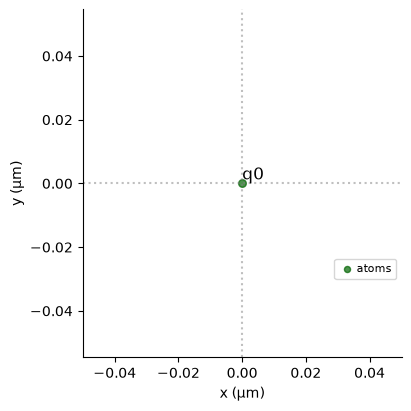

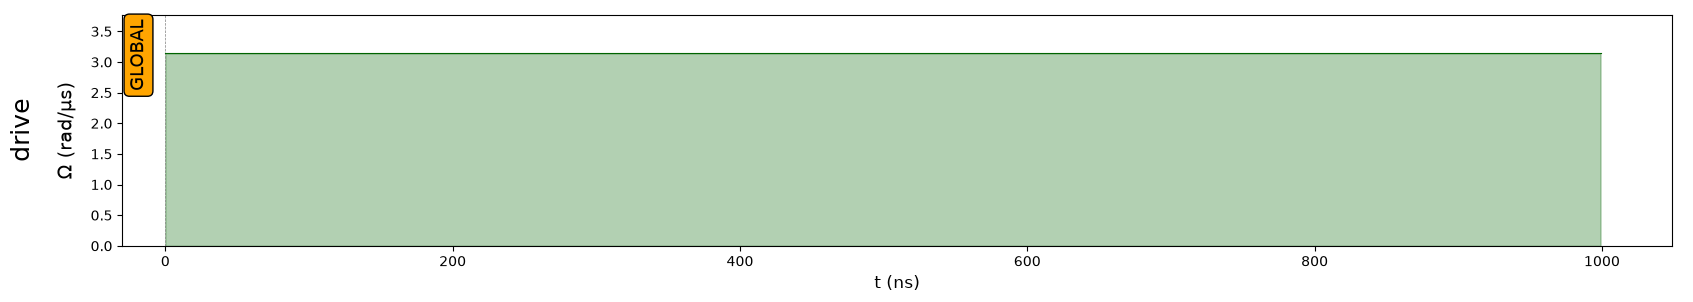

In [2]:
device = AnalogDevice
single_atom = Register.from_coordinates([(0, 0)], prefix="q")
single_atom.draw()

single_sequence = Sequence(single_atom, device)
single_sequence.declare_channel("drive", "rydberg_global")
single_sequence.add(Pulse.ConstantPulse(1000, np.pi, 0, 0), "drive")
single_sequence.draw(mode="input")

In [3]:
single_result = QutipBackendV2(single_sequence).run()
print(single_result.final_bitstrings)

Counter({'1': 1000})


Here `0` means ground state and `1` means Rydberg state, so almost all measurements should be `1`.

## Prepare an alternating pattern on a 3 x 3 array

Nearby Rydberg excitations repel each other. We choose the spacing so nearest neighbors interact with strength `U = 2*pi` rad/us. Then we slowly change the drive to favor excitations while discouraging adjacent excited atoms. This is adiabatic antiferromagnetic state preparation.

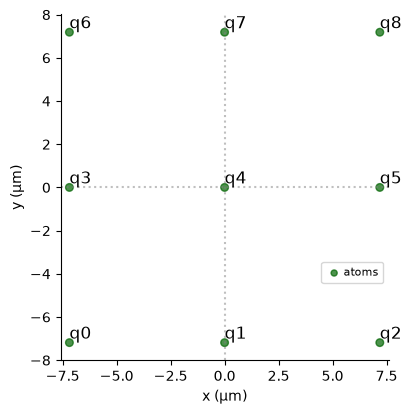

Nearest-neighbor spacing: 7.19 um


In [4]:
U = 2 * np.pi
omega_max = 2 * U
delta_start, delta_end = -6 * U, 2 * U
spacing = (device.interaction_coeff / U) ** (1 / 6)

array = Register.square(3, spacing=spacing, prefix="q")
array.draw()
print(f"Nearest-neighbor spacing: {spacing:.2f} um")

The sequence has three parts: turn up the amplitude, sweep detuning from negative to positive, then turn the amplitude off. Amplitude controls the drive strength; detuning controls how favorable an excitation is.

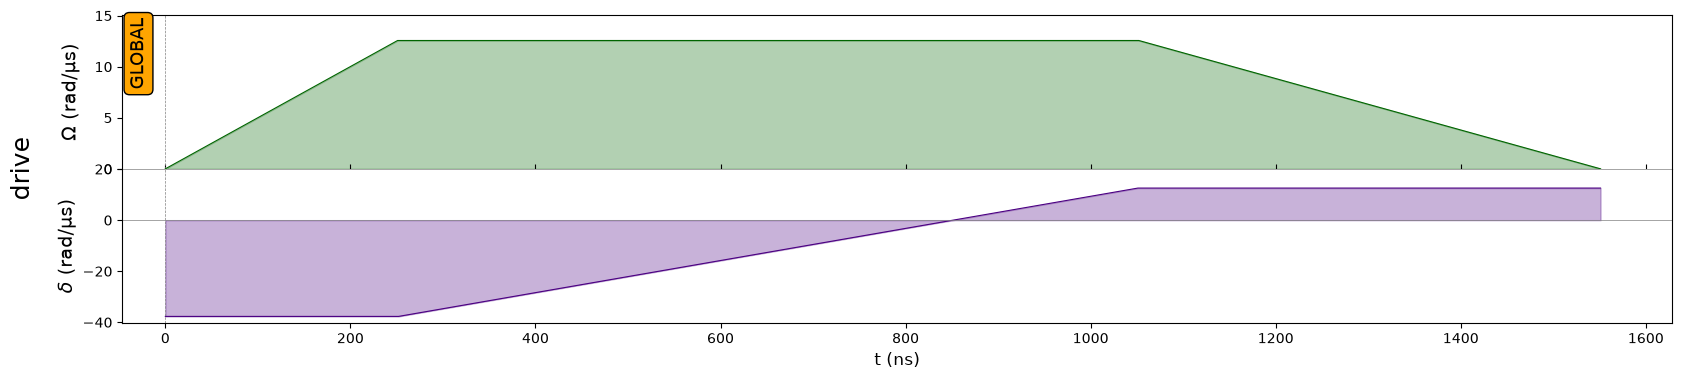

In [5]:
rise = Pulse.ConstantDetuning(
    RampWaveform(252, 0, omega_max), delta_start, 0
)
sweep = Pulse.ConstantAmplitude(
    omega_max, RampWaveform(800, delta_start, delta_end), 0
)
fall = Pulse.ConstantDetuning(
    RampWaveform(500, omega_max, 0), delta_end, 0
)

array_sequence = Sequence(array, device)
array_sequence.declare_channel("drive", "rydberg_global")
for pulse in (rise, sweep, fall):
    array_sequence.add(pulse, "drive")
array_sequence.draw(mode="input")

Most common bitstrings: [('101010101', 136), ('101000101', 36), ('101010111', 26), ('101001110', 26), ('101001101', 25), ('101110101', 24), ('101100101', 23), ('110001101', 21), ('101100011', 20), ('011100101', 18)]


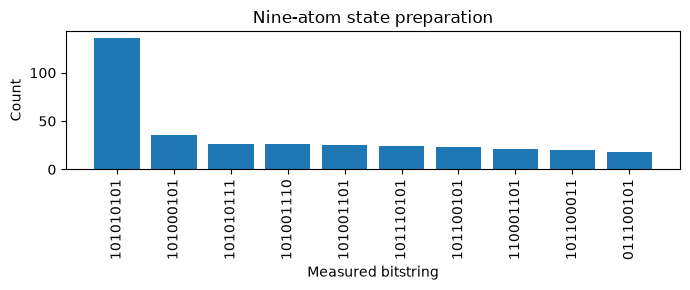

In [6]:
array_result = QutipBackendV2(array_sequence).run()
counts = array_result.final_bitstrings
most_common = counts.most_common(10)
print("Most common bitstrings:", most_common)

plt.figure(figsize=(7, 3))
plt.bar([bits for bits, count in most_common], [count for bits, count in most_common])
plt.xticks(rotation=90)
plt.xlabel("Measured bitstring")
plt.ylabel("Count")
plt.title("Nine-atom state preparation")
plt.tight_layout()
plt.show()

The checkerboard pattern `101010101` should be prominent: excited atoms avoid their nearest neighbors. Preparation is not perfect, and sampled counts vary between runs. This nine-atom simulation may take longer than the single-atom example.